# TAD calling

This tutorial calls topologically associating domains (TADs) from
chromatin traces with `uchrom.strc.tad.call_tads_by_pval` (also
`uc.tl.call_tads`), an independent implementation of the ArcFISH p-value
TAD caller (Yu et al. 2025, bioRxiv 10.1101/2025.11.26.690837), including
its nested hierarchy.  It then runs the callers on a **backed**
`.chromdata.zarr` store with `streaming=True`, projects TADs and loops onto
bins and spots with `uchrom.strc.enrichment.add_structural_features`, and
finally compares imaging TADs with directionality-index TADs called on Hi-C
of the same loci (`uchrom.strc.tad.call_tads_di`).  Data: Takei et al. 2021
(*Nature* 590:344) mESC DNA seqFISH+ at 25 kb (4DN `4DNFIHF3JCBY`), and Su
et al. 2020 (*Cell* 182:1641) IMR90 chr21, 651 loci of 50 kb with the
authors' binned Rao 2014 Hi-C (Zenodo 3928890, 261 MB).  Runtime: 2–4 minutes.

**How the caller works** (per chromosome): after the same per-axis variance
normalisation as the loop caller, each locus `b` is tested as a boundary.
The loci within the window on its left and on its right form two candidate
domains; if `b` is a boundary, pairs *within* a side vary less than pairs
*across* it.  A per-axis F-test of within / across variance, combined over
the axes with ACAT, gives one p-value per locus; local minima that pass
BH-FDR are the boundaries.  With `hierarchical=True` the result has
several levels: **level 1 uses every boundary** (the finest partition) and
each further level drops the weakest remaining boundary, giving coarser,
nested TADs.

In [1]:
import shutil
import subprocess
import sys
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from chromdata import ChromData
import uchrom as uc

plt.rcParams["figure.dpi"] = 90


def find_repo_root(start=Path.cwd()):
    for p in [start, *start.parents]:
        if (p / "example-data" / "README.md").exists():
            return p
    raise FileNotFoundError("run this notebook inside the U-Chrom repository")


REPO = find_repo_root(); DATA = REPO / "example-data"; OUT = REPO / "tutorials" / "_out"; OUT.mkdir(exist_ok=True)


def ensure_data(rel, flag):
    """``DATA / rel``; fetched with ``example-data/download_data.py --<flag>`` when absent
    (every dataset is listed in example-data/README.md)."""
    path = DATA / rel
    if not path.exists():
        print(f"{rel} not found: running example-data/download_data.py --{flag}")
        subprocess.run([sys.executable, str(DATA / "download_data.py"), f"--{flag}"], check=True)
    return path

## Load the Takei 2021 traces

In [2]:
fofct = ensure_data("4DNFIHF3JCBY.csv", "takei")
cd = ChromData.from_fofct(fofct)
cd

ChromData: n_spots=316995, n_traces=8285, n_cells=201, n_bins=1200
  spots:   ['chrom', 'start', 'end', 'trace_id', 'spot_id', 'cell_id', 'extra_cell_roi_id', 'bin_id']
  uns:     ['fofct_header', 'xyz_unit', 'genome_assembly']

## TADs on one chromosome

`window_bp` is the whole test window around a locus (half of it on each
side).  ArcFISH's `TADCaller(window=100 kb)` uses 100 kb on **each** side,
so `window_bp=2e5` reproduces its setting; the uChrom default (`1e5`,
±50 kb) is compared below.

In [3]:
from uchrom.strc.tad import TADCallerParams, call_tads_by_pval

ARC = TADCallerParams(window_bp=2e5)          # ±100 kb, as ArcFISH; fdr_cutoff=0.1, 4 levels
tads6 = call_tads_by_pval(cd, chrom="chr6", params=ARC, key_added="tads.chr6", verbose=True)
print(tads6.groupby("level").size().rename("TADs").to_frame().T)
tads6[tads6.level == 1]

[tad/chr6] variance cube...
[tad/chr6] filter + normalise...


[tad/chr6] axis weights: [0.335 0.33  0.335]
level  1  2  3  4
TADs   7  6  5  4


,chrom,start,end,level,score,pval,fdr
0,chr6,49375000,49500000,1,4.210355,6.160907e-05,1.601836e-04
1,chr6,49500000,49900000,1,4.210355,6.160907e-05,1.601836e-04
2,chr6,49900000,50075000,1,5.986241,1.032189e-06,4.472821e-06
3,chr6,50075000,50275000,1,7.595458,2.538293e-08,1.649891e-07
4,chr6,50275000,50550000,1,7.595458,2.538293e-08,1.649891e-07
5,chr6,50550000,50600000,1,9.341988,4.550010e-10,5.915013e-09
6,chr6,50625000,50925000,1,9.341988,4.550010e-10,5.915013e-09


`score` / `pval` / `fdr` of a TAD are those of the stronger of its two
boundaries.  The table is stored as a `domain` interval table:

In [4]:
cd.intervals["tads.chr6"].kind, cd.results.record("tads.chr6").function

('domain', 'uchrom.strc.tad.call_tads_by_pval')

## TADs on the median distance map

A good call outlines the low-distance blocks along the diagonal of the
population median distance map.  Left: the finest partition (level 1);
right: level 4, after the three weakest boundaries have been dropped — the
coarser TADs contain the finer ones.

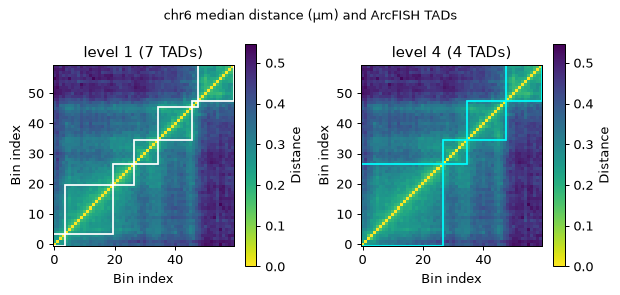

In [5]:
from matplotlib.patches import Rectangle
from uchrom.fea import distance_map
from uchrom.pl import plot_distance_matrix

dm = distance_map(cd, "chr6")
starts = dm.bins["start"].to_numpy()


def draw_tads(ax, table, **kw):
    for _, r in table.iterrows():
        a = int(np.searchsorted(starts, r.start))
        b = int(np.searchsorted(starts, r.end))          # end is exclusive
        ax.add_patch(Rectangle((a - 0.5, a - 0.5), b - a, b - a, fill=False, **kw))


top = int(tads6.level.max())
fig, axes = plt.subplots(1, 2, figsize=(7, 3.2))
plot_distance_matrix(dm.matrix, title=f"level 1 ({(tads6.level == 1).sum()} TADs)", ax=axes[0])
draw_tads(axes[0], tads6[tads6.level == 1], edgecolor="white", lw=1.4)
plot_distance_matrix(dm.matrix, title=f"level {top} ({(tads6.level == top).sum()} TADs)", ax=axes[1])
draw_tads(axes[1], tads6[tads6.level == top], edgecolor="cyan", lw=1.4)
fig.suptitle("chr6 median distance (µm) and ArcFISH TADs", fontsize=10)
plt.tight_layout(); plt.show()

## All chromosomes, and the window size

`chrom=None` (the default) calls every chromosome and merges the tables
under one key, `"tads.arcfish"`.  We count the boundaries (level-1 TAD
edges inside each imaged region) for the two window settings.

In [6]:
tads = uc.tl.call_tads(cd, params=ARC)        # method="arcfish" -> call_tads_by_pval
region = cd.bins.groupby("chrom", observed=True).agg(lo=("start", "min"), hi=("end", "max"))


def boundaries(table):
    rows = []
    for chrom, g in table[table.level == 1].groupby("chrom"):
        edges = set(g.start) | set(g.end)
        rows += [(chrom, e) for e in sorted(edges - {region.lo[chrom], region.hi[chrom]})]
    return pd.DataFrame(rows, columns=["chrom", "pos"])


summary = []
for name, table in {"window_bp=1e5 (±50 kb, uChrom default)": uc.tl.call_tads(cd, key_added=None),
                    "window_bp=2e5 (±100 kb, ArcFISH)": tads}.items():
    b = boundaries(table)
    summary.append({"setting": name, "boundaries": len(b), "regions with a boundary": b.chrom.nunique(),
                    "level-1 TADs": int((table.level == 1).sum())})
pd.DataFrame(summary).set_index("setting")

,boundaries,regions with a boundary,level-1 TADs
setting,,,
"window_bp=1e5 (±50 kb, uChrom default)",67,16,81
"window_bp=2e5 (±100 kb, ArcFISH)",120,20,130


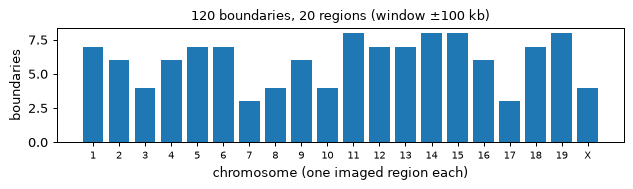

In [7]:
b = boundaries(tads)
order = sorted(region.index, key=lambda c: int(c[3:]) if c[3:].isdigit() else 99)
counts = b.groupby("chrom").size().reindex(order, fill_value=0)
fig, ax = plt.subplots(figsize=(7, 2.2))
ax.bar(range(len(counts)), counts.to_numpy(), color="tab:blue")
ax.set_xticks(range(len(counts)), [c.replace("chr", "") for c in counts.index], fontsize=8)
ax.set_xlabel("chromosome (one imaged region each)"); ax.set_ylabel("boundaries")
ax.set_title(f"{len(b)} boundaries, 20 regions (window ±100 kb)", fontsize=10)
plt.tight_layout(); plt.show()

**How this compares with the paper.**  ArcFISH reports 105 TAD boundaries
on this dataset (insulation score: 135).  With the ArcFISH window this
implementation calls somewhat more (120, table above); the halved window
of the uChrom default finds about half as many and none in four regions.
The remaining difference comes from implementation details (for example,
uChrom applies BH-FDR to the local minima only, ArcFISH to every locus).

## Streaming on a backed store, and projecting structures onto bins

For data that do not fit in memory, write a `.chromdata.zarr` store and
open it **backed**: only the small tables are loaded, coordinates stay on
disk.  `from_fofct(..., out=)` streams the FOF-CT table into a store
chunk by chunk and returns it opened backed.

In [8]:
store = OUT / "takei2021_25kb.chromdata.zarr"
if store.exists():
    shutil.rmtree(store)
back = ChromData.from_fofct(fofct, out=store)
print(back)
print(f"working-memory budget of the streaming paths: {uc.settings.memory_budget / 1e9:.1f} GB")

ChromData (backed: takei2021_25kb.chromdata.zarr): n_spots=316995, n_traces=8285, n_cells=201, n_bins=1200
  spots:   ['chrom', 'start', 'end', 'trace_id', 'spot_id', 'cell_id', 'extra_cell_roi_id', 'bin_id']
  uns:     ['fofct_header', 'xyz_unit', 'genome_assembly']
working-memory budget of the streaming paths: 15.7 GB


On a backed object the ArcFISH TAD and loop callers stream over the traces
of each chromosome (`streaming=True` is the default there; it is spelled
out here): the variance statistics are accumulated in trace batches with
memory `O(n_bins²)` instead of `O(n_traces × n_bins²)`, in float64.  The
calls equal the in-memory ones; p-values differ only by rounding (the
in-memory call above ran in float32 if it used Apple MPS).  The calls are
stored in the backed object's `intervals` / `results`, like in memory.

In [9]:
t0 = time.perf_counter()
tads_b = uc.tl.call_tads(back, params=ARC, streaming=True)
loops_b = uc.tl.call_loops(back, streaming=True)
print(f"streaming calls: {time.perf_counter() - t0:.1f} s; {len(tads_b)} TAD rows, {len(loops_b)} loops")

key = ["chrom", "start", "end", "level"]
same = tads_b[key].reset_index(drop=True).equals(tads[key].reset_index(drop=True))
print("same TADs as in memory:", same,
      "| max relative p-value difference:", float(np.max(np.abs(tads_b.pval.to_numpy() / tads.pval.to_numpy() - 1))))
print(back.intervals)

streaming calls: 15.9 s; 397 TAD rows, 5 loops
same TADs as in memory: True | max relative p-value difference: 0.007190897910361649
IntervalStore({'tads.arcfish': <domain, 397 rows>, 'loops.axiswise_f': <pair, 5 rows>})


`add_structural_features` turns the interval tables into per-locus
features in `bin_tracks` (prefix `strc.`): distance to the nearest TAD
boundary, whether the locus lies in a TAD, whether it overlaps a loop
anchor (and how many), and the distance to the nearest anchor.  It finds
the calls under their default keys (`"tads.arcfish"`, `"loops.axiswise_f"`,
`"compartments.axes_pc"` when present) and records the features in the
feature registry.

In [10]:
from uchrom.strc.enrichment import add_structural_features

features = add_structural_features(back)
print(list(back.bin_tracks.columns))
back.bins.join(back.bin_tracks).query("`strc.loop_anchor_overlap` == 1")

['strc.distance_to_tad_boundary', 'strc.inside_tad', 'strc.loop_anchor_overlap', 'strc.loop_anchor_count', 'strc.distance_to_loop_anchor']


,chrom,start,end,strc.distance_to_tad_boundary,strc.inside_tad,strc.loop_anchor_overlap,strc.loop_anchor_count,strc.distance_to_loop_anchor
bin_id,,,,,,,,
212,chr12,63200000,63225000,162500.0,1.0,1.0,1.0,0.0
214,chr12,63300000,63325000,62500.0,1.0,1.0,1.0,0.0
695,chr2,109900000,109925000,12500.0,1.0,1.0,1.0,0.0
706,chr2,110200000,110225000,12500.0,1.0,1.0,1.0,0.0
823,chr4,90550000,90575000,287500.0,1.0,1.0,1.0,0.0
828,chr4,90700000,90725000,137500.0,1.0,1.0,1.0,0.0
936,chr6,50300000,50325000,37500.0,1.0,1.0,1.0,0.0
945,chr6,50525000,50550000,12500.0,1.0,1.0,1.0,0.0
1142,chrX,75375457,75400457,12500.0,1.0,1.0,1.0,0.0


Bin tracks follow every spot through its `bin_id`.  Reading one
chromosome from the store gives an in-memory object whose
`tracks_spot_view()` lines the features up with the spots — e.g. to compare
the 3-D distance of the two anchors of the chr2 loop with the distance of
other pairs at the same genomic separation, trace by trace.

In [11]:
chr2 = back.get_chrom("chr2")                    # reads one chromosome partition
spots = chr2.spots_with_loci().join(chr2.tracks_spot_view(["strc.loop_anchor_overlap",
                                                            "strc.distance_to_tad_boundary"]))
print(spots.groupby("strc.loop_anchor_overlap").size().rename("spots"))

loop = loops_b[loops_b.chrom1 == "chr2"].iloc[0]
sep = loop.start2 - loop.start1
xyz = pd.DataFrame(chr2.coords, columns=["x", "y", "z"]).assign(
    trace=chr2.spots["trace_id"].astype(str).to_numpy(), start=spots["start"].to_numpy())
xyz = xyz.drop_duplicates(["trace", "start"], keep="last").set_index(["trace", "start"])


def pair_distances(s1, s2):
    a, b = xyz.xs(s1, level="start"), xyz.xs(s2, level="start")
    both = a.index.intersection(b.index)
    return np.linalg.norm(a.loc[both].to_numpy() - b.loc[both].to_numpy(), axis=1)


anchors = pair_distances(loop.start1, loop.start2)
chr2_starts = np.sort(chr2.bins.loc[chr2.bins.chrom == "chr2", "start"].to_numpy())
others = np.concatenate([pair_distances(s, s + sep) for s in chr2_starts
                         if s + sep in set(chr2_starts) and s != loop.start1])
print(f"anchor pair {loop.start1:,}-{loop.start2:,}: median {np.median(anchors):.3f} µm over {len(anchors)} traces; "
      f"other pairs {sep // 1000} kb apart: {np.median(others):.3f} µm")

strc.loop_anchor_overlap
0.0    13319
1.0      533
Name: spots, dtype: int64
anchor pair 109,900,000-110,200,000: median 0.218 µm over 171 traces; other pairs 300 kb apart: 0.349 µm


The structures live in the backed object's small tables.  `write` saves
everything to a new store (a backed object loads its data for that, so
this is meant for stores that fit in memory; the original store is not
changed):

In [12]:
saved = OUT / "takei2021_25kb_structures.chromdata.zarr"
if saved.exists():
    shutil.rmtree(saved)
back.write(saved)
again = ChromData.read(saved, backed=True)
print(again.intervals)
print("results:", list(again.results))
print("bin tracks:", list(again.bin_tracks.columns))

IntervalStore({'tads.arcfish': <domain, 397 rows>, 'loops.axiswise_f': <pair, 5 rows>})
results: ['tads.arcfish', 'loops.axiswise_f', 'bin_features']
bin tracks: ['strc.distance_to_tad_boundary', 'strc.inside_tad', 'strc.loop_anchor_overlap', 'strc.loop_anchor_count', 'strc.distance_to_loop_anchor']


## Imaging TADs vs Hi-C TADs on the same loci (Su et al. 2020)

Su et al. 2020 traced the q-arm of chr21 (651 loci of 50 kb, 7,591
chromosome copies in IMR90 cells) and summed Rao et al. 2014 IMR90 Hi-C
reads into the same loci.  That allows a direct comparison: ArcFISH TADs on
the imaging, and Dixon et al. 2012 directionality-index (DI) TADs on the
Hi-C with `call_tads_di`.

In [13]:
def load_su2020_chr21():
    """Su et al. 2020 chr21 tracing (IMR90, hg38) as a ChromData.

    One trace per imaged chromosome copy; loci with a missing coordinate
    (not detected) are left out; nm → µm.  ``bin_tracks["n_genes"]`` counts
    the genes Su et al. list for each locus (the genes whose nascent
    transcription they imaged).
    """
    tsv = ensure_data("su2020_imr90/chromosome21.tsv", "su2020_chr21")
    raw = pd.read_csv(tsv, sep="\t", usecols=[0, 1, 2, 3, 4, 5])
    raw.columns = ["z", "x", "y", "locus", "copy", "genes"]
    loc = raw["locus"].str.extract(r"(chr\w+):(\d+)-(\d+)")
    raw["chrom"] = loc[0]
    raw["start"] = loc[1].astype(int) - 1          # "chr21:10400001-10450001" -> [10,400,000, 10,450,000)
    raw["end"] = loc[2].astype(int) - 1
    ok = raw[["x", "y", "z"]].notna().all(axis=1).to_numpy()
    spots = raw.loc[ok, ["chrom", "start", "end"]].assign(trace_id=raw.loc[ok, "copy"].astype(str))
    su = ChromData(coords=raw.loc[ok, ["x", "y", "z"]].to_numpy(float) / 1000.0,
                   spots=spots.reset_index(drop=True),
                   uns={"genome_assembly": "hg38", "xyz_unit": "micron",
                        "source": "Su et al. 2020 Cell 182:1641, chromosome21.tsv (Zenodo 3928890)"})
    per_locus = raw.drop_duplicates("locus")
    n_genes = per_locus["genes"].fillna("").map(lambda s: sum(1 for g in s.split(";") if g))
    keyed = pd.Series(n_genes.to_numpy(), index=pd.MultiIndex.from_frame(per_locus[["chrom", "start", "end"]]))
    bins = su.bins
    su.bin_tracks = pd.DataFrame(
        {"n_genes": keyed.reindex(pd.MultiIndex.from_frame(bins[["chrom", "start", "end"]].astype({"chrom": str})))
                         .fillna(0).to_numpy()},
        index=bins.index)
    print(f"{raw['copy'].nunique()} chromosome copies, {raw['locus'].nunique()} loci, "
          f"{1 - ok.mean():.1%} of the locus positions not detected")
    return su


def load_su2020_hic():
    """The authors' Rao 2014 IMR90 Hi-C, summed into the same 651 loci (hg38): (counts, locus table)."""
    tsv = ensure_data("su2020_imr90/Hi-C_contacts_chromosome21.tsv", "su2020_chr21")
    hic = pd.read_csv(tsv, sep="\t", index_col=0)
    loc = hic.index.str.extract(r"(chr\w+):(\d+)-(\d+)")
    loci = pd.DataFrame({"chrom": loc[0].to_numpy(), "start": loc[1].astype(int).to_numpy() - 1,
                         "end": loc[2].astype(int).to_numpy() - 1})
    return hic.to_numpy(float), loci

In [14]:
su = load_su2020_chr21()
t0 = time.perf_counter()
tads_su = uc.tl.call_tads(su, params=TADCallerParams(window_bp=2e5, hierarchical=False))
b_img = tads_su.start.iloc[1:].to_numpy()       # each TAD after the first starts at a boundary
print(f"ArcFISH on imaging: {len(tads_su)} TADs, {len(b_img)} boundaries ({time.perf_counter() - t0:.0f} s)")

7591 chromosome copies, 651 loci, 6.5% of the locus positions not detected


ArcFISH on imaging: 92 TADs, 91 boundaries (33 s)


`call_tads_di` reads the contact matrix of a `.cool` file linked to the
`ChromData` (`cd.link_cool`; the file stays external).  We write the
authors' binned Hi-C as a cooler; cooler bins must tile the chromosome, so
each bin runs from one imaged locus to the next (plus an empty leading
bin).  The `DICallerParams` defaults (a 50-bin window, smoothing over 10 %
and a minimum TAD of 5 % of the bins) suit a whole chromosome at 40 kb;
for these 651 loci we use a 10-locus window (≈0.5 Mb), 1 % smoothing and a
0.5 % minimum size.

In [15]:
import cooler
from uchrom.strc.tad import DICallerParams

H, loci = load_su2020_hic()
cool = OUT / "su2020_chr21_rao2014.cool"
if cool.exists():
    cool.unlink()
bins = pd.DataFrame({"chrom": "chr21",
                     "start": np.r_[0, loci.start.to_numpy()],
                     "end": np.r_[loci.start.to_numpy(), loci.end.iat[-1]]})
i, j = np.triu_indices(len(H))
pixels = pd.DataFrame({"bin1_id": i + 1, "bin2_id": j + 1, "count": H[i, j].round().astype(np.int64)})
cooler.create_cooler(str(cool), bins, pixels[pixels["count"] > 0], assembly="hg38")
cooler.balance_cooler(cooler.Cooler(str(cool)), store=True)          # ICE weights

su.link_cool(cool, key="rao2014", label="Rao 2014 IMR90 Hi-C in the Su 2020 loci")
DI = DICallerParams(window=10, smoothing_param=0.01, min_size_frac=0.005)
di = uc.tl.call_tads(su, method="di", contacts="rao2014", params=DI)
b_hic = di.start.iloc[1:].to_numpy()
print(f"DI on Hi-C: {len(di)} domains, {len(b_hic)} boundaries")
print(su.intervals)

DI on Hi-C: 44 domains, 43 boundaries
IntervalStore({'tads.arcfish': <domain, 92 rows>, 'tads.di': <domain, 44 rows>})


How often does a Hi-C (DI) boundary fall within one locus of an imaging
(ArcFISH) boundary, compared with what random positions would give?  The
same question for a coarser DI call (20-locus window, more smoothing)
shows how much the answer depends on the DI settings.

In [16]:
pos = {s: k for k, s in enumerate(loci.start)}                 # locus start -> index
img_idx = np.array([pos[s] for s in b_img])
chance = np.mean(np.min(np.abs(np.arange(len(loci))[:, None] - img_idx[None, :]), axis=1) <= 1)
coarse = uc.tl.call_tads(su, method="di", contacts="rao2014", key_added=None,
                         params=DICallerParams(window=20, smoothing_param=0.02, min_size_frac=0.01))
for name, table in (("DI, 10-locus window", di), ("DI, 20-locus window", coarse)):
    hic_idx = np.array([pos[s] for s in table.start.iloc[1:] if s in pos])
    near = np.min(np.abs(hic_idx[:, None] - img_idx[None, :]), axis=1) <= 1
    print(f"{name}: {near.mean():.0%} of {len(hic_idx)} boundaries within one locus of an ArcFISH boundary "
          f"(random positions: {chance:.0%})")

DI, 10-locus window: 63% of 43 boundaries within one locus of an ArcFISH boundary (random positions: 41%)
DI, 20-locus window: 46% of 28 boundaries within one locus of an ArcFISH boundary (random positions: 41%)


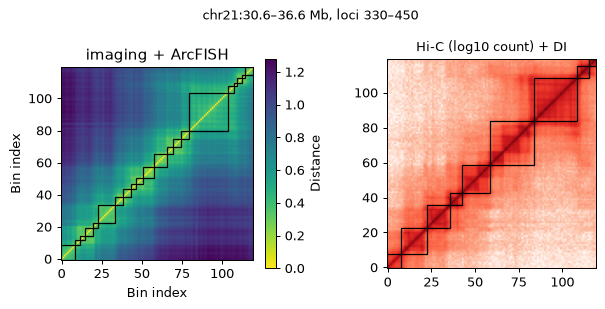

In [17]:
lo, hi = 330, 450                                             # a stretch of chr21q
window = (su.spots["start"] >= loci.start[lo]) & (su.spots["start"] < loci.start[hi])
dm_su = distance_map(su[window.to_numpy()], "chr21")


def draw_domains(ax, table):
    for _, r in table.iterrows():
        a = int(np.searchsorted(loci.start, r.start)) - lo       # first locus
        b = int(np.searchsorted(loci.start, r.end)) - lo         # exclusive end
        a, b = max(a, 0), min(b, hi - lo)
        if b - a >= 2:
            ax.add_patch(Rectangle((a - 0.5, a - 0.5), b - a, b - a, fill=False, edgecolor="k", lw=1))


fig, axes = plt.subplots(1, 2, figsize=(7, 3.3))
plot_distance_matrix(dm_su.matrix, title="imaging + ArcFISH", ax=axes[0])
axes[1].imshow(np.log10(H[lo:hi, lo:hi] + 1), cmap="Reds", origin="lower")
axes[1].set_title("Hi-C (log10 count) + DI", fontsize=10)
draw_domains(axes[0], tads_su)
draw_domains(axes[1], di)
mb = f"chr21:{loci.start[lo] / 1e6:.1f}–{loci.start[hi] / 1e6:.1f} Mb, loci {lo}–{hi}"
fig.suptitle(mb, fontsize=10)
plt.tight_layout(); plt.show()

**How this compares with the paper.**  On these data ArcFISH reports 49
boundaries (insulation score: 53) and stronger CTCF / cohesin enrichment at
its boundaries.  This implementation calls more boundaries at the same
window (see the count above), so its partition of chr21 is finer.  The Hi-C
boundaries of the DI caller fall near imaging boundaries more often than
random positions would, but far from one to one, and the agreement depends
strongly on the DI window and smoothing: with the coarser setting it is
close to chance.

## Notes

- `call_tads_by_pval`, `call_loops_axiswise_f` and
  `call_compartments_axes_pc` share the variance normalisation of
  `uchrom.fea.arc`.
- For a flat partition use `hierarchical=False` (or `level == 1`).
- `uc.tl.call_tads(cd, method=...)` dispatches to `"arcfish"` / `"pval"`
  (this caller), `"fishnet"` (single-allele domains) and `"di"` (Hi-C).
- The deprecated helpers `uchrom.strc.call_structures_multi` /
  `call_tads_multi` / … still work (with a `DeprecationWarning`); the
  callers with `chrom=None` replace them.

## Next steps

- `fishnet_domains` — domains on single alleles, compared with these
  population boundaries.
- `loop_calling` — loops on the same data.
- `compartment` — A/B compartments on Su 2020 chr21, validated against the
  same Hi-C.